# Calibration of the muon momenta

**Owner: B.** Measure the momentum scale of the muons in the two $\eta$ regions with the
J/ψ peak, and deliver it in `calibration.json` through a pull request. The code goes in
`calibration.py`; this notebook only calls it.

Lines marked `# TODO` are commented out: they need functions that are not written yet.
Uncomment them when the function is in `main` (A, C) or in your branch (B).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import dimuon
import mc
from calibration import ETA_SPLIT, M_JPSI, Calibration, fit_peak

GROUP = 1           # TODO: your group number (1 to 8)
assert 1 <= GROUP <= 8, 'Set GROUP to the group number your teacher gave you (1 to 8)'

## 1. The control sample

Muon pairs with a mass near the J/ψ. How many events? Which columns have missing values?

In [2]:
control_raw = pd.read_hdf('data/bsmumu.h5', f'group{GROUP}/control')
print(len(control_raw), 'events')
control_raw.head()

10000 events


,mu1_pt,mu1_eta,mu1_phi,mu1_q,mu2_pt,mu2_eta,mu2_phi,mu2_q,mu1_pid,mu2_pid,vtx_chi2,trigger
0,1.38985,3.49887,1.58556,-1,2.05065,4.35531,-0.31454,-1,0.19720,0.68018,5.69895,True
1,2.87597,4.42042,-2.25346,-1,2.19108,4.80718,-1.02596,-1,0.87597,0.96382,0.53968,True
2,2.28833,2.41935,1.68519,-1,4.15062,3.40862,1.66951,1,0.08720,0.12008,10.16495,True
3,2.85605,4.48792,-1.88178,-1,1.20218,4.38075,2.50601,1,0.74059,0.79574,0.43806,True
4,3.06985,3.36796,-1.94712,-1,7.76930,3.52572,-1.33937,1,0.95708,0.67385,0.45700,False


In [3]:
control_raw.isna().sum()

mu1_pt        0
mu1_eta       0
mu1_phi       0
mu1_q         0
mu2_pt        0
mu2_eta       0
mu2_phi       0
mu2_q         0
mu1_pid      95
mu2_pid     107
vtx_chi2     94
trigger       0
dtype: int64

## 2. The MC

Same format as the data, perfectly calibrated, and with the truth: how many J/ψ were
generated.

In [4]:
mc_control, truth = mc.generate('control', n_bkg=8000, seed=1)
print(len(mc_control), 'events; truth:', truth)
mc_control.head()

10000 events; truth: {'jpsi': 2000}


,mu1_pt,mu1_eta,mu1_phi,mu1_q,mu2_pt,mu2_eta,mu2_phi,mu2_q,mu1_pid,mu2_pid,vtx_chi2,trigger
0,2.19420,3.96894,-0.40038,1,1.30424,4.57823,2.20813,-1,0.25651,0.92073,24.92790,True
1,1.76190,4.14744,2.78565,1,1.68433,4.05536,0.87228,-1,0.21588,0.84800,5.63567,True
2,3.67312,2.59578,1.35433,-1,2.49559,3.23268,0.72040,1,0.19161,0.68867,9.42667,True
3,1.66025,3.57627,-2.17375,1,1.56803,4.27931,-0.05162,-1,0.51454,0.17901,3.84402,False
4,5.28169,3.03305,-2.60399,1,2.59761,2.23518,-2.76302,-1,0.96063,0.87983,0.83974,True


Do data and MC agree in the variables that the calibration does not change? How many
events have both muons in the same $\eta$ region?

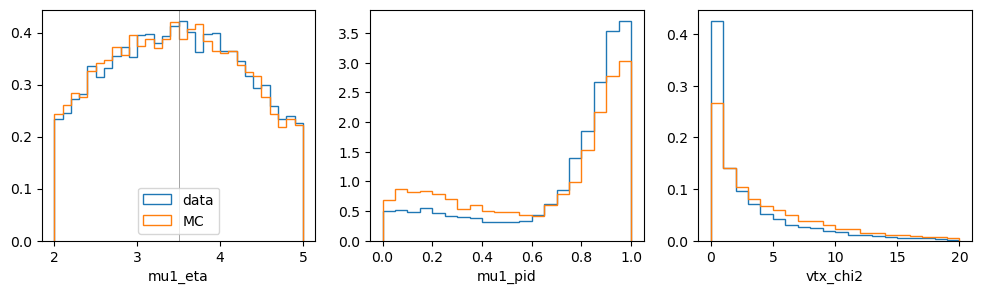

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, (col, bins) in zip(axes, [('mu1_eta', np.linspace(2, 5, 31)),
                                  ('mu1_pid', np.linspace(0, 1, 21)),
                                  ('vtx_chi2', np.linspace(0, 20, 21))]):
    ax.hist(control_raw[col], bins, density=True, histtype='step', label='data')
    ax.hist(mc_control[col], bins, density=True, histtype='step', label='MC')
    ax.set_xlabel(col)
axes[0].axvline(ETA_SPLIT, color='grey', lw=0.5)
axes[0].legend();

In [6]:
for name, df in [('data', control_raw), ('MC', mc_control)]:
    low1, low2 = df['mu1_eta'] < ETA_SPLIT, df['mu2_eta'] < ETA_SPLIT
    print(f'{name:4s}  both low: {(low1 & low2).mean():.2f}  both high: {(~low1 & ~low2).mean():.2f}'
          f'  mixed: {(low1 != low2).mean():.2f}')

data  both low: 0.35  both high: 0.33  mixed: 0.32
MC    both low: 0.36  both high: 0.33  mixed: 0.31


## 3. First on a toy peak

Until A and C are merged there is no mass to fit. Write `fit_peak` on a J/ψ peak made
with numpy, where you know the truth: a Gaussian over a flat background.

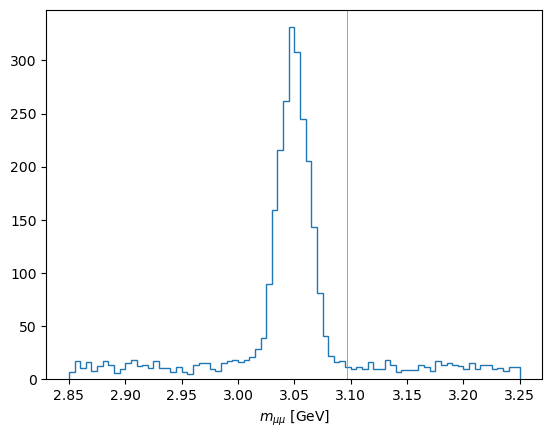

In [7]:
rng = np.random.default_rng(0)
toy_truth = {'mean': 3.05, 'width': 0.013}
m_toy = np.concatenate([rng.normal(toy_truth['mean'], toy_truth['width'], 2000),
                        rng.uniform(2.85, 3.25, 1000)])

plt.hist(m_toy, bins=np.linspace(2.85, 3.25, 81), histtype='step')
plt.axvline(M_JPSI, color='grey', lw=0.5)
plt.xlabel(r'$m_{\mu\mu}$ [GeV]');

In [8]:
# TODO (B): uncomment when fit_peak is written
mean, error, width = fit_peak(m_toy)
print(f'mean = {mean:.4f} ± {error:.4f} GeV, width = {1000 * width:.1f} MeV')
print('truth:', toy_truth)

mean = 3.0495 ± 0.0003 GeV, width = 13.3 MeV
truth: {'mean': 3.05, 'width': 0.013}


## 4. Selection and mass

Needs `dimuon.select` (C) and `dimuon.invariant_mass` (A): pull `main` once they are
merged, and uncomment. Where is the peak in the data, and where in the MC? The J/ψ mass
is 3.0969 GeV.

2664 events selected


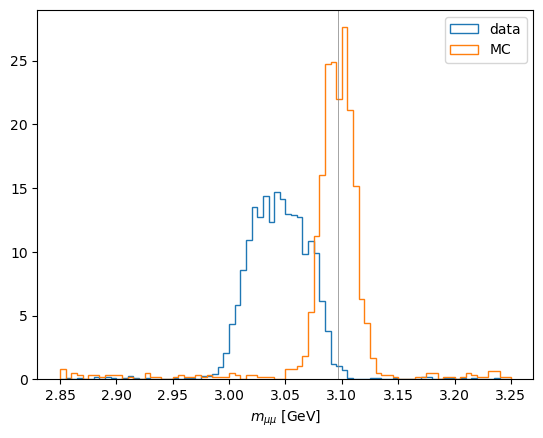

In [9]:
# TODO (A, C): uncomment when select and invariant_mass are in main
control = dimuon.select(control_raw)
m = dimuon.invariant_mass(control)
m_mc = dimuon.invariant_mass(dimuon.select(mc_control))
print(f'{len(control)} events selected')

bins = np.linspace(2.85, 3.25, 81)
plt.hist(m, bins, density=True, histtype='step', label='data')
plt.hist(m_mc, bins, density=True, histtype='step', label='MC')
plt.axvline(M_JPSI, color='grey', lw=0.5)
plt.xlabel(r'$m_{\mu\mu}$ [GeV]')
plt.legend();

## 5. First on the MC

The MC is perfectly calibrated: the fit must give scales close to 1. If not, the method is
wrong, not the detector.

In [10]:
# TODO (B): uncomment when Calibration.fit is written
Calibration().fit(dimuon.select(mc_control))

Calibration(low=1.0001, high=0.9995)

## 6. The scales of the data

Save them in `calibration.json`, and open a pull request with it: the analysis team reads
this file.

In [11]:
# TODO (B)
cal = Calibration().fit(control)
cal.save()
cal

Calibration(low=0.9909, high=0.9753)

## 7. Check with the mixed events

Events with one muon in each region were **not** used in the fit. Before the correction,
where is their J/ψ peak? After `cal.apply`, is it at 3.0969 GeV? Plot both histograms.

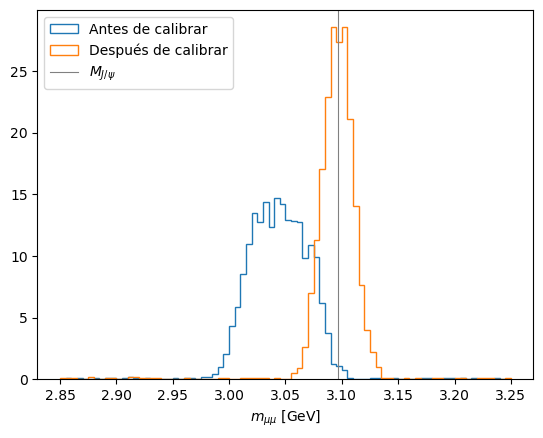

Posiciones de los picos:
Antes: 3.0437882187768057 GeV
Después: 3.096255866745113 GeV


In [13]:
# Masa antes de la calibración
m_before = dimuon.invariant_mass(control)

# Masa después de la calibración
control_cal = cal.apply(control)
m_after = dimuon.invariant_mass(control_cal)

# Histogramas de ambos
bins = np.linspace(2.85, 3.25, 81) #límites del anterior histograma

plt.hist(m_before, bins=bins, density=True, histtype='step', label='Antes de calibrar')

plt.hist(m_after, bins=bins, density=True, histtype='step', label='Después de calibrar')

plt.axvline(M_JPSI, color='grey', lw=0.8, label=r'$M_{J/\psi}$') 

plt.xlabel(r'$m_{\mu\mu}$ [GeV]')
plt.legend()
plt.show()


#Posiciones de los picos
print('Posiciones de los picos:')
print('Antes:', fit_peak(m_before)[0], 'GeV')
print('Después:', fit_peak(m_after)[0], 'GeV')

**CONCLUSIÓN**

El procedimiento de calibración implementado devuelve unos factores de calibración para los datos reales cercanos a 1 (0,9909 y 0.9753 para las regiones de baja y alta pseudorapidez, respectivamente). Observamos un desplazamiento del pico del mesón desde 3,0438 GeV hasta 3, 0963 GeV, acercándolo así al valor de referencia de 3,0969 GeV. 

Estos resultados desmuestran que la calibración corrige la escala de momento de forma eficaz y permite reconstruír la masa del  $J/\psi$ con un valor cercano al esperado.